BÀI 3: SO SÁNH CÁC THUẬT TOÁN HỒI QUY TRÊN DIABETES

=== BẢNG TỔNG HỢP SO SÁNH KẾT QUẢ ===
       Thuật toán     MAE    RMSE     R2
 SVR (RBF Kernel) 39.4187 51.0641 0.5078
Gradient Boosting 42.5461 52.3725 0.4823
 Ridge Regression 42.8120 53.7775 0.4541
Linear Regression 42.7941 53.8534 0.4526
    Decision Tree 47.0454 59.7408 0.3264


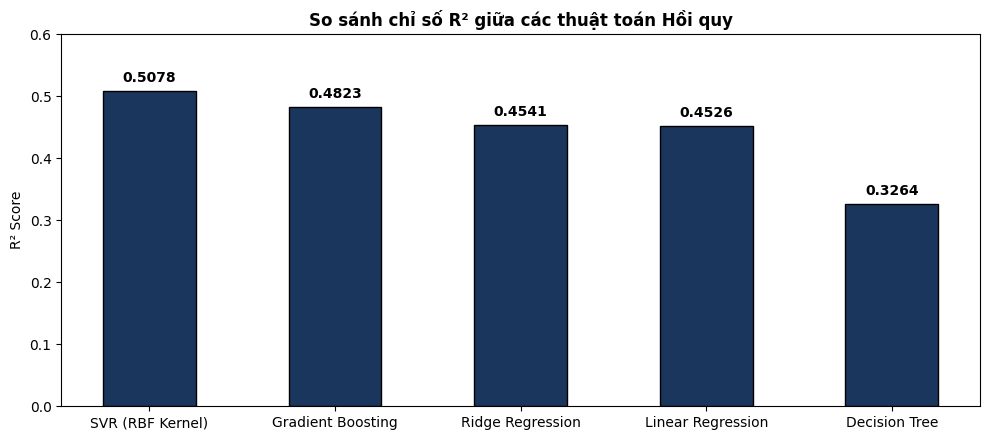

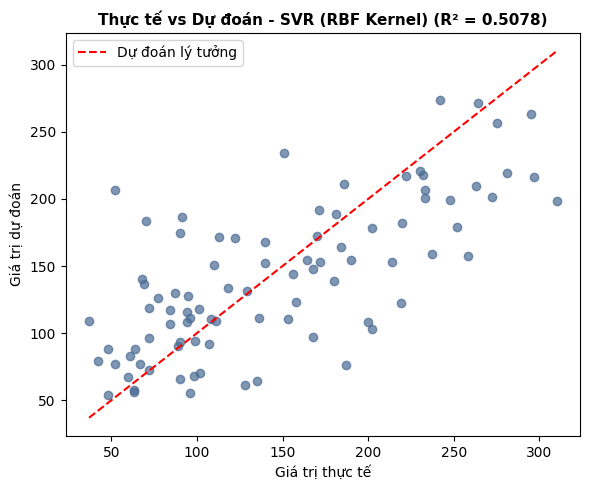


HOÀN THÀNH BÀI 3!


In [1]:
# ==============================================================================
# BÀI 3: SO SÁNH CÁC THUẬT TOÁN HỒI QUY TRÊN DỮ LIỆU DIABETES
# Tác giả: Cấn Xuân Hồng - MSSV: 24174800181 - Lớp: DHKM18A2HN
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Tải và chia dữ liệu
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Định nghĩa danh sách mô hình
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "SVR (RBF Kernel)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=100, epsilon=0.1)),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)
}

print("="*60)
print("BÀI 3: SO SÁNH CÁC THUẬT TOÁN HỒI QUY TRÊN DIABETES")
print("="*60)

# 3. Huấn luyện và Đánh giá
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions[name] = preds

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results.append({
        "Thuật toán": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False).reset_index(drop=True)

print("\n=== BẢNG TỔNG HỢP SO SÁNH KẾT QUẢ ===")
print(results_df.round(4).to_string(index=False))

# 4. Trực quan hóa kết quả R2
plt.figure(figsize=(10, 4.5))
bars = plt.bar(results_df['Thuật toán'], results_df['R2'], color='#1b365d', edgecolor='black', width=0.5)
plt.title("So sánh chỉ số R² giữa các thuật toán Hồi quy", fontsize=12, fontweight='bold')
plt.ylabel("R² Score")
plt.ylim(0, 0.6)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# 5. Biểu đồ Actual vs Predicted của mô hình tốt nhất
best_model_name = results_df.iloc[0]['Thuật toán']
best_pred = predictions[best_model_name]

plt.figure(figsize=(6, 5))
plt.scatter(y_test, best_pred, alpha=0.7, color='#4b6b94')
min_val = min(y_test.min(), best_pred.min())
max_val = max(y_test.max(), best_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Dự đoán lý tưởng')
plt.title(f"Thực tế vs Dự đoán - {best_model_name} (R² = {results_df.iloc[0]['R2']:.4f})", fontsize=11, fontweight='bold')
plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.legend()
plt.tight_layout()
plt.show()

print("\nHOÀN THÀNH BÀI 3!")